<a href="https://colab.research.google.com/github/MariaMinottaZ/movie-review-sentiment-analysis/blob/main/Dataset_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset description

For this experiment is going to be used IMDB Dataset of 50K Movie Reviews dataset, which can be found on Kaggle.

IMDB dataset has 50K movie reviews. It provides a set of 25,000 highly polar movie reviews for training and 25,000 for testing. So, predict the number of positive and negative reviews using either classification or deep learning algorithms.




# Import dataset

In [ ]:
import kagglehub

path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Path to dataset files: /kaggle/input/imdb-dataset-of-50k-movie-reviews


Extract content

In [ ]:
import pandas as pd
import os

csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print(csv_files)

['/kaggle/input/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv']


In [ ]:
columns = [
    "review",
    "sentiment"
]

df = pd.read_csv(
    csv_files[0],
    encoding="ISO-8859-1",
    header=None,
    names=columns
)

# Cleaning data

In [ ]:
df = df[df["sentiment"] != "sentiment"].copy()

# EDA

## Initial look

In [ ]:
print("Shape:", df.shape)

df.head()

Shape: (50001, 2)


,review,sentiment
0,review,sentiment
1,One of the other reviewers has mentioned that ...,positive
2,A wonderful little production. <br /><br />The...,positive
3,I thought this was a wonderful way to spend ti...,positive
4,Basically there's a family where a little boy ...,negative


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50001 non-null  object
 1   sentiment  50001 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


## Missing values and duplicate rows

In [ ]:
missing = pd.DataFrame({
    "missing_values": df.isnull().sum(),
    "percentage": df.isnull().mean() * 100
})

missing

,missing_values,percentage
review,0,0.0
sentiment,0,0.0


In [ ]:
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 418


In [ ]:
df[["sentiment", "review"]].sample(10, random_state=42)

,sentiment,review
33553,positive,If you watch this series you will get an inter...
9427,positive,"In The White Balloon and Crimson Gold, the two..."
199,positive,If you keep rigid historical perspective out o...
12447,positive,"this movie probably had a $750 budget, and sti..."
39489,positive,This was on the Saturday before Halloween this...
42725,positive,I've watched this movie on a fairly regular ba...
10822,negative,(some spoilers) - as if you wouldn't know how ...
49499,positive,"Okay, I didn't get the Purgatory thing the fir..."
4144,positive,"This film is titled ""Junior Pilot"" here on IMD..."
36958,positive,Even a bad Julie Andrews Musical is worth watc...


## Data distribution by sentiment

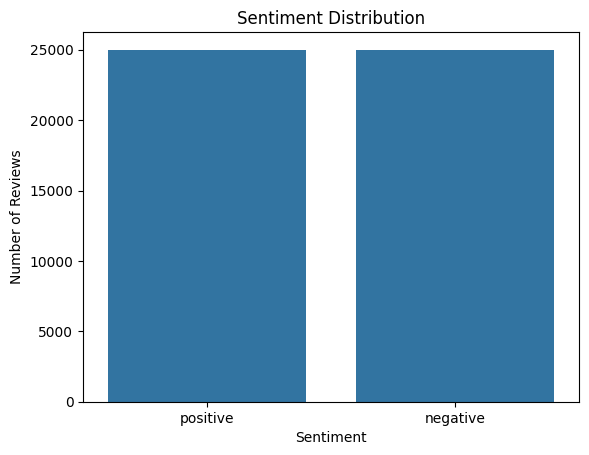

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df["sentiment"].value_counts()

df["sentiment"].value_counts(normalize=True) * 100

sns.countplot(data=df, x="sentiment")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

The dataset is balanced

## Data distribution by length

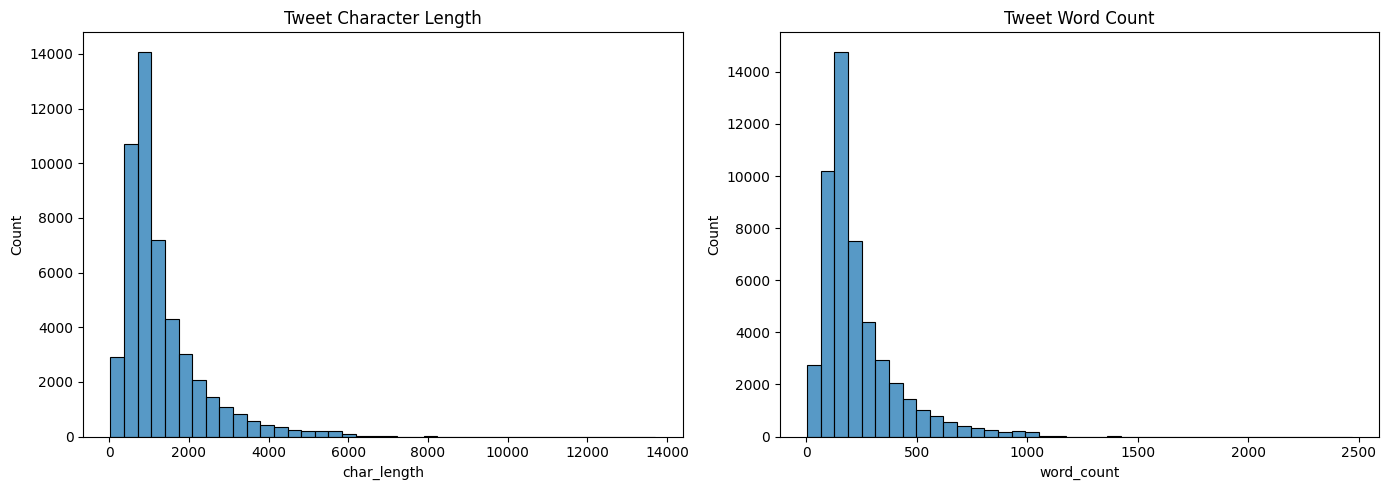

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df["char_length"] = df["review"].str.len()

df["word_count"] = df["review"].str.split().str.len()

df[["char_length", "word_count"]].describe()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["char_length"],
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Tweet Character Length")

sns.histplot(
    df["word_count"],
    bins=40,
    ax=axes[1]
)

axes[1].set_title("Tweet Word Count")

plt.tight_layout()
plt.show()

Dataset grouped by character and word count

In [ ]:
df.groupby("sentiment")[
    ["char_length", "word_count"]
].describe()

char_length                                                       \
                count        mean          std   min    25%    50%     75%   
sentiment                                                                    
negative      25000.0  1294.29280   946.157246  32.0  706.0  973.0  1568.0   
positive      25000.0  1325.04752  1031.818046  65.0  691.0  968.0  1614.0   

                   word_count                                             \
               max      count       mean         std   min    25%    50%   
sentiment                                                                  
negative    8969.0    25000.0  229.46980  164.955363   4.0  128.0  174.0   
positive   13704.0    25000.0  232.85532  177.504710  10.0  125.0  172.0   

                          
             75%     max  
sentiment                 
negative   278.0  1522.0  
positive   284.0  2470.0

In [ ]:
patterns = {
    "mentions": r"@\w+",
    "hashtags": r"#\w+",
    "urls": r"http\S+|www\.\S+",
    "numbers": r"\d+",
    "exclamation_marks": r"!",
    "question_marks": r"\?"
}

for name, pattern in patterns.items():

    count = df["text"].str.contains(
        pattern,
        regex=True,
        na=False
    ).sum()

    print(f"{name}: {count}")

## Samples by sentiment

In [ ]:
negative_tweets = df[df["sentiment"] == "negative"]["review"]
positive_tweets = df[df["sentiment"] == "positive"]["review"]

print("NEGATIVE EXAMPLES")

for tweet in negative_tweets.sample(10, random_state=42):
    print("-", tweet)

print("\nPOSITIVE EXAMPLES")

for tweet in positive_tweets.sample(10, random_state=42):
    print("-", tweet)

NEGATIVE EXAMPLES
- I was looking forward to seeing Bruce Willis in this, especially since I remember being mesmerised by the original when I was young.<br /><br />This movie is a perfect example of how movie companies can take a very good story and dumb it down until it's just another formula ridden hype of the fabled American law enforcement system/army VS, (the Russians.... no sorry the cold war is over, make that WITH the Russians) VS the TERRORISTS, similar to probably 50 other movies.<br /><br />Furthermore it treats its audience like a bunch of idiots. The choice of weapon is well, plain ridiculous, are we seriously expected to believe that the world's most feared and experienced hit man/terrorist would select that for an assasination?<br /><br />The whole point of the original story was the tense dual of intellects between the ordinary detective who is given the responsibility and the professional who crafts a ruthless but elegant plan to reach his target and then get away. Non

## High frequency words and n-grams

### High frequency words

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer

custom_stopwords = list(ENGLISH_STOP_WORDS) + ["br"]

vectorizer = CountVectorizer(
    stop_words=custom_stopwords,
    max_features=30
)

X = vectorizer.fit_transform(df["review"].dropna())

word_frequency = pd.DataFrame({
    "word": vectorizer.get_feature_names_out(),
    "frequency": X.sum(axis=0).A1
})

word_frequency = word_frequency.sort_values(
    "frequency",
    ascending=False
)

word_frequency.head(20)

,word,frequency
19,movie,87955
7,film,79682
14,like,40170
11,just,35181
9,good,29752
27,time,25099
25,story,23112
23,really,23093
1,bad,18471
21,people,18183


Graphed

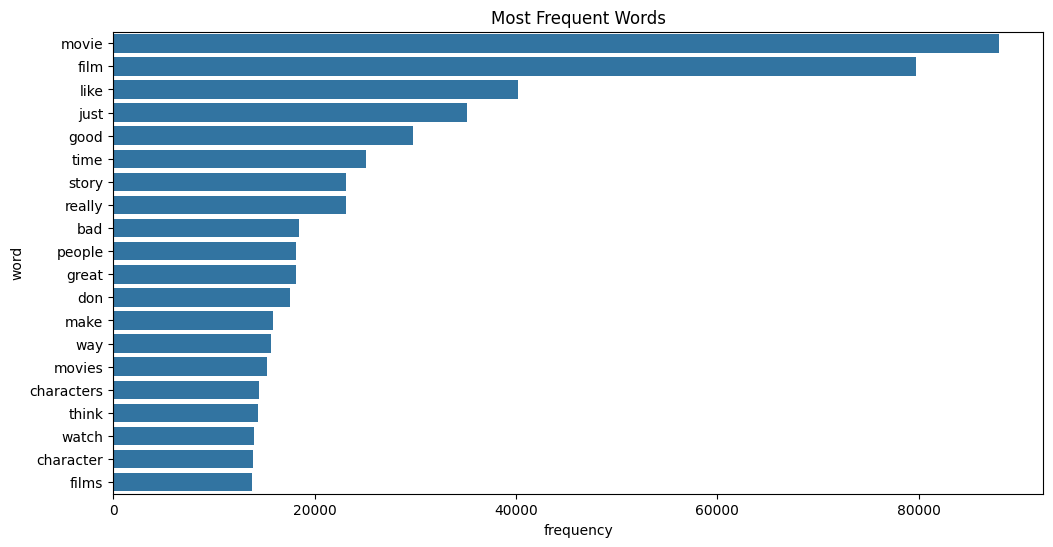

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=word_frequency.head(20),
    x="frequency",
    y="word"
)

plt.title("Most Frequent Words")
plt.show()

### High frequency words by sentiment

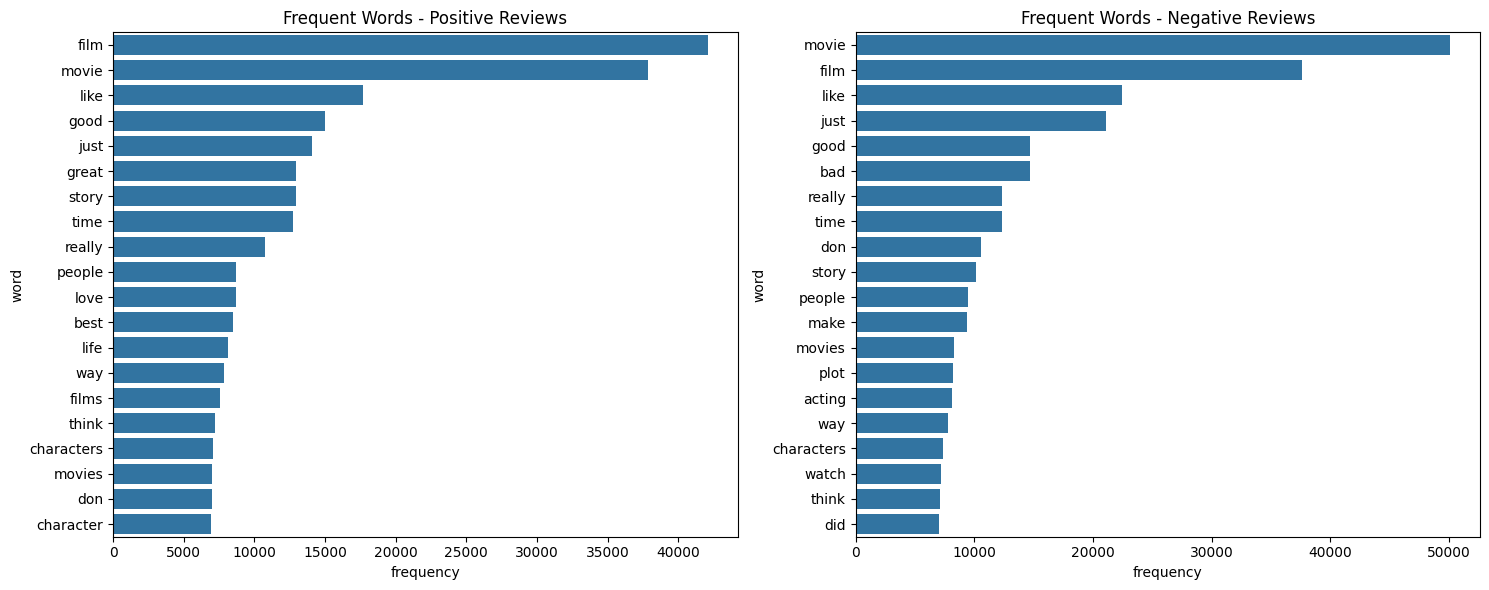

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

def get_frequent_words(data, n=20):

    vectorizer = CountVectorizer(
        stop_words=custom_stopwords,
        max_features=100
    )

    X = vectorizer.fit_transform(data)

    frequencies = pd.DataFrame({
        "word": vectorizer.get_feature_names_out(),
        "frequency": X.sum(axis=0).A1
    })

    return frequencies.sort_values(
        "frequency",
        ascending=False
    ).head(n)

positive_words = get_frequent_words(
    df[df["sentiment"] == "positive"]["review"]
)

negative_words = get_frequent_words(
    df[df["sentiment"] == "negative"]["review"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=positive_words,
    x="frequency",
    y="word",
    ax=axes[0]
)

axes[0].set_title("Frequent Words - Positive Reviews")

sns.barplot(
    data=negative_words,
    x="frequency",
    y="word",
    ax=axes[1]
)

axes[1].set_title("Frequent Words - Negative Reviews")

plt.tight_layout()
plt.show()

### High frequency n-grams

In [ ]:
vectorizer = CountVectorizer(
    stop_words=custom_stopwords,
    ngram_range=(2, 3),
    max_features=30
)

X = vectorizer.fit_transform(df["review"].dropna())

In [ ]:
ngram_frequencies = pd.DataFrame({
    "ngram": vectorizer.get_feature_names_out(),
    "frequency": X.sum(axis=0).A1
})

ngram_frequencies = ngram_frequencies.sort_values(
    by="frequency",
    ascending=False
)

ngram_frequencies.head(30)

,ngram,frequency
24,ve seen,4167
23,special effects,2249
1,don know,2197
13,low budget,1823
12,looks like,1678
28,year old,1598
15,movie just,1537
25,waste time,1523
4,good movie,1514
22,sci fi,1392


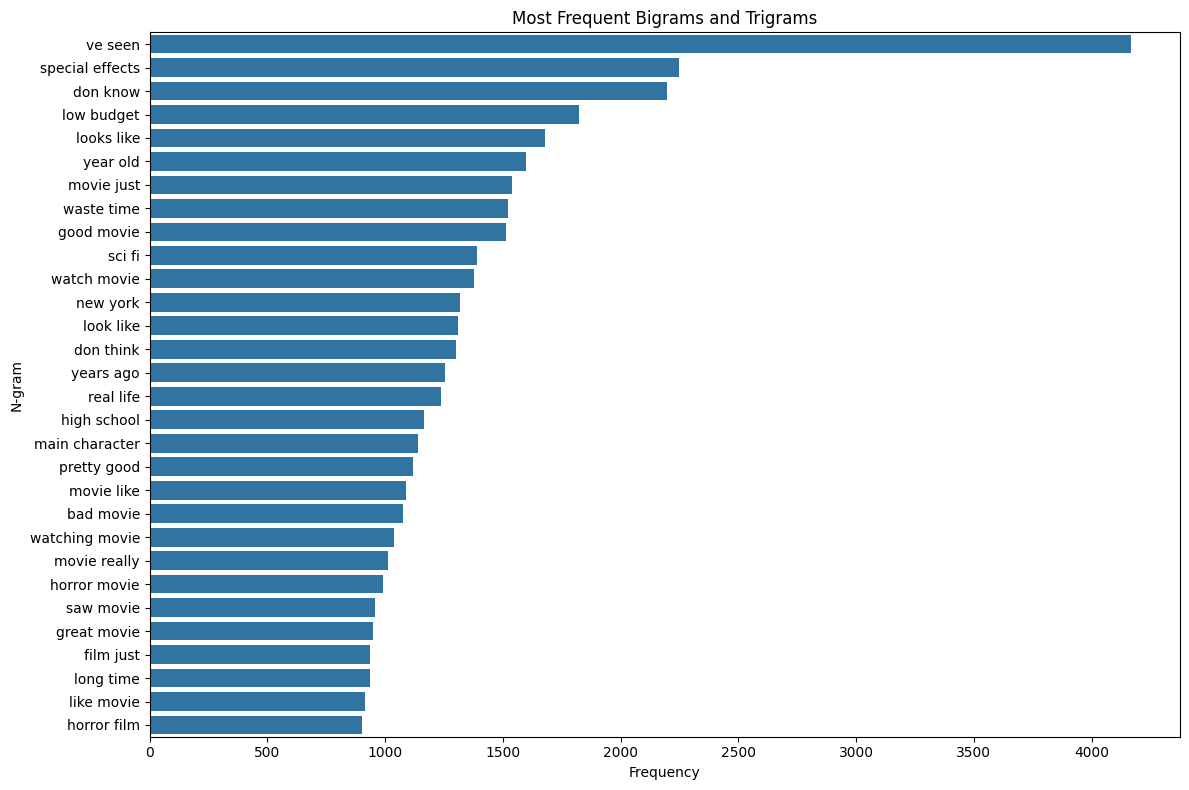

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.barplot(
    data=ngram_frequencies.head(30),
    x="frequency",
    y="ngram"
)

plt.title("Most Frequent Bigrams and Trigrams")
plt.xlabel("Frequency")
plt.ylabel("N-gram")

plt.tight_layout()
plt.show()

### High frequency n-grams by sentiment

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

def get_frequent_ngrams(data, n=20):

    vectorizer = CountVectorizer(
        stop_words=custom_stopwords,
        ngram_range=(2, 3),
        max_features=100
    )

    X = vectorizer.fit_transform(data)

    frequencies = pd.DataFrame({
        "ngram": vectorizer.get_feature_names_out(),
        "frequency": X.sum(axis=0).A1
    })

    return frequencies.sort_values(
        "frequency",
        ascending=False
    ).head(n)

positive_ngrams = get_frequent_ngrams(
    df[df["sentiment"] == "positive"]["review"]
)

negative_ngrams = get_frequent_ngrams(
    df[df["sentiment"] == "negative"]["review"]
)


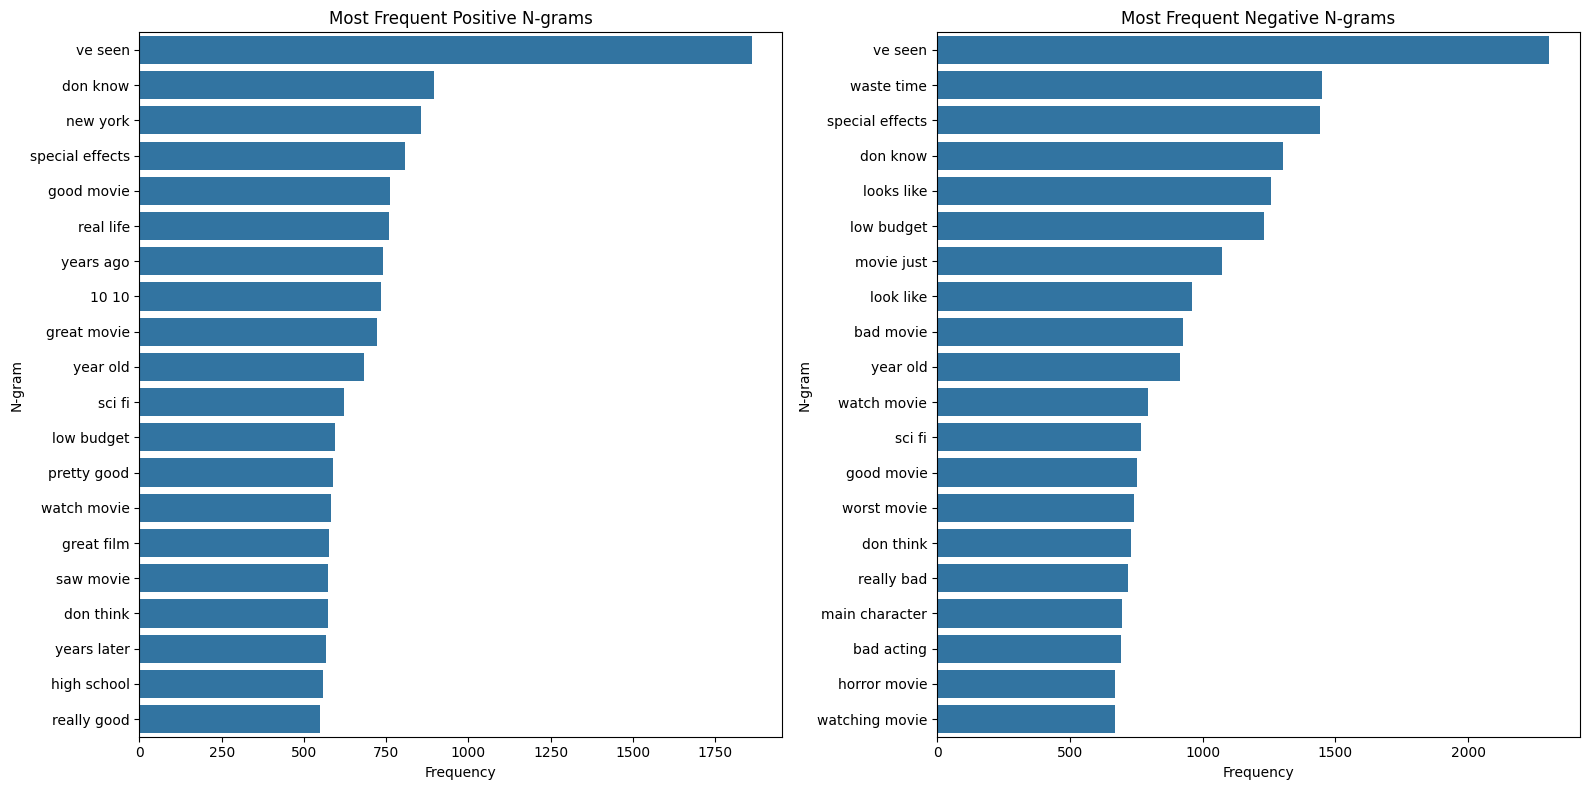

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sns.barplot(
    data=positive_ngrams,
    x="frequency",
    y="ngram",
    ax=axes[0]
)

axes[0].set_title("Most Frequent Positive N-grams")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("N-gram")


sns.barplot(
    data=negative_ngrams,
    x="frequency",
    y="ngram",
    ax=axes[1]
)

axes[1].set_title("Most Frequent Negative N-grams")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("N-gram")

plt.tight_layout()
plt.show()

# Text preprocessing

Function to detect text

In [ ]:
import re

def clean_text(text):

    text = text.lower()

    text = re.sub(r"<br\s*/?>", " ", text)

    text = re.sub(r"http\S+|www\.\S+", "", text)

    text = re.sub(r"https\S+|www\.\S+", "", text)

    text = re.sub(r"[^a-z\s]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
df["clean_text"] = df["review"].apply(clean_text)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)